# DNN Assignment 2 - Problem 2: Transformer from scratch

**Name:** Amit Kumar Mohanty &nbsp;&nbsp; **Student ID:** 2026AJ05290

Here I write attention, multi-head attention and an encoder block myself, then use them for
Task A (HAR classification) and Task B (a character-level Shakespeare language model).
PyTorch's attention/Transformer classes are only used in the test cells, to check my code.

My choices: d = 128 for the language model, d = 64 for the HAR encoder, 4 heads, seeds 11, 23, 37.
The 3-token example in task 1 is my own.

Run problem1.ipynb first (Task A compares with its results). Then Colab T4, Runtime > Run all.

In [3]:
# settings
STUDENT_ID = "2026AJ05290"
SEEDS = [11, 23, 37]          # same as problem 1
BATCH = 64
LR = 1e-3                     # Adam, same for all models
CLIP = 1.0
# Task A - HAR encoder (same 30 epochs as problem 1)
HAR_EPOCHS = 30
D_HAR, HEADS_HAR, LAYERS_HAR, PATCH, DROPOUT = 64, 4, 2, 8, 0.1
# Task B - char language model
CTX, D_LM, HEADS_LM, LAYERS_LM = 128, 128, 4, 4
LM_BATCH = 64
LM_STEPS = 3000               # main model
ABL_STEPS = 1500              # ablations; the 4-head result is taken from the main run at this step
EVAL_EVERY = 100
TOP_K = 20                    # sampling only picks from the 20 best characters
LM_SEED = SEEDS[0]
QUICK = False                 # True: tiny run, only to test the code

In [4]:
import math, os, pickle, random, time, urllib.request, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import f1_score

if QUICK:
    HAR_EPOCHS, LM_STEPS, ABL_STEPS, EVAL_EVERY = 1, 40, 20, 10

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| running on', device)

# relative paths; shared files go one folder up when we are inside problem2/
ROOT = Path('..') if Path.cwd().name == 'problem2' else Path('.')
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
DATA = ROOT / 'data'; DATA.mkdir(exist_ok=True)
CACHE = ROOT / 'cache'; CACHE.mkdir(exist_ok=True)     # saved runs, delete it to retrain
RESULTS = ROOT / 'results.csv'                         # shared with problem 1
SAMPLES = Path('generated_samples.txt')

COLUMNS = ['problem', 'model', 'seed', 'seq_len', 'test_acc', 'macro_f1', 'test_mse', 'params',
           'sec_per_epoch', 'val_loss_nats', 'bits_per_char', 'notes']

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def log_result(**row):
    # add one row to results.csv (columns that don't apply stay empty)
    df = pd.DataFrame([{c: row.get(c, '') for c in COLUMNS}], columns=COLUMNS)
    df.to_csv(RESULTS, mode='a', header=not RESULTS.exists(), index=False)

def nparams(model):
    return sum(p.numel() for p in model.parameters())

HW = device.type + (f'-{torch.cuda.get_device_name(0)}' if device.type == 'cuda' else f'-{torch.get_num_threads()}thr')

def cached(name, train_fn):
    # load the run if it is saved already, otherwise train it and save it
    path = CACHE / f'{name}.pkl'
    if path.exists():
        with open(path, 'rb') as f:
            return pickle.load(f)
    result = train_fn()
    result['hw'] = HW
    tmp = path.with_suffix('.tmp')       # write to tmp first so a crash doesn't leave a broken file
    with open(tmp, 'wb') as f:
        pickle.dump(result, f)
    os.replace(tmp, path)
    return result

# remove old problem 2 rows, so running again doesn't add them twice
if RESULTS.exists():
    old = pd.read_csv(RESULTS)
    old[~old['problem'].astype(str).str.startswith(('problem2', 'bonus'))].to_csv(RESULTS, index=False)
print('results go to', RESULTS)

PyTorch 2.14.1+cu130 | running on cuda
results go to ../results.csv


## Task 1 - Scaled dot-product attention
scores = Q Kᵀ / √d_k, weights = softmax(scores), output = weights × V.
The causal mask hides later tokens, so a token only sees itself and the ones before it.
I wrote softmax myself too (subtract the row max first so exp doesn't overflow).

In [5]:
def softmax(x, dim=-1):
    x = x - x.amax(dim=dim, keepdim=True)        # masked scores are -inf, they become 0
    e = torch.exp(x)
    return e / e.sum(dim=dim, keepdim=True)

def attention(q, k, v, mask=None, dropout_p=0.0, training=False):
    # q (..., n_q, d_k), k (..., n_k, d_k), v (..., n_k, d_v)
    # mask: True = allowed to look; returns output (..., n_q, d_v) and weights (..., n_q, n_k)
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)          # (..., n_q, n_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float('-inf'))
    w = softmax(scores, dim=-1)                                # rows sum to 1
    if dropout_p > 0 and training:
        w = F.dropout(w, dropout_p)
    return w @ v, w                                            # (..., n_q, d_v)

def causal_mask(n, device=None):
    return torch.tril(torch.ones(n, n, dtype=torch.bool, device=device))   # (n, n), True on and below the diagonal

In [6]:
# tests: rows sum to 1, same as PyTorch's attention, causal mask hides the future
set_seed(0)
q, k, v = torch.randn(2, 3, 7, 16), torch.randn(2, 3, 7, 16), torch.randn(2, 3, 7, 16)   # (B, heads, n, d_k)
out, w = attention(q, k, v)
assert torch.allclose(w.sum(-1), torch.ones(2, 3, 7), atol=1e-6)
assert (out - F.scaled_dot_product_attention(q, k, v)).abs().max() < 1e-5
m = causal_mask(7)
out_c, w_c = attention(q, k, v, m)
assert (out_c - F.scaled_dot_product_attention(q, k, v, attn_mask=m)).abs().max() < 1e-5
assert (out_c - F.scaled_dot_product_attention(q, k, v, is_causal=True)).abs().max() < 1e-5
assert torch.all(w_c.masked_select(~m) == 0)                    # no weight on future positions
assert torch.allclose(w_c.sum(-1), torch.ones(2, 3, 7), atol=1e-6)
assert torch.allclose(softmax(q), torch.softmax(q, -1), atol=1e-6)
print('attention tests passed; max |mine - torch| =', (out - F.scaled_dot_product_attention(q, k, v)).abs().max().item())

attention tests passed; max |mine - torch| = 3.5762786865234375e-07


### My 3-token example (d_k = 2)
Q = K = [[1, 0], [0, 1], [1, 1]], V = [[1, 2], [3, 4], [5, 6]]

Q Kᵀ = [[1, 0, 1], [0, 1, 1], [1, 1, 2]], divided by √2: row 1 = [0.7071, 0, 0.7071],
row 2 = [0, 0.7071, 0.7071], row 3 = [0.7071, 0.7071, 1.4142]. With e^0.7071 = 2.0281 and e^1.4142 = 4.1133:
* row 1: [2.0281, 1, 2.0281] / 5.0562 = [0.4011, 0.1978, 0.4011] -> output **[3.0000, 4.0000]**
* row 2: [1, 2.0281, 2.0281] / 5.0562 = [0.1978, 0.4011, 0.4011] -> output **[3.4067, 4.4067]**
* row 3: [2.0281, 2.0281, 4.1133] / 8.1695 = [0.2483, 0.2483, 0.5035] -> output **[3.5105, 4.5105]**

With the causal mask: token 1 only sees itself -> **[1, 2]**. Token 2: [1, 2.0281] / 3.0281 = [0.3302, 0.6698]
-> **[2.3395, 3.3395]**. Token 3 sees everything anyway, so it stays the same.

In [7]:
Q = torch.tensor([[1., 0.], [0., 1.], [1., 1.]]); K = Q.clone(); V = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])
hand_w = torch.tensor([[0.4011, 0.1978, 0.4011], [0.1978, 0.4011, 0.4011], [0.2483, 0.2483, 0.5035]])
hand_out = torch.tensor([[3.0, 4.0], [3.4067, 4.4067], [3.5105, 4.5105]])
hand_out_causal = torch.tensor([[1.0, 2.0], [2.3395, 3.3395], [3.5105, 4.5105]])
o, w = attention(Q, K, V)
oc, wc = attention(Q, K, V, causal_mask(3))
print('weights\n', w.numpy().round(4), '\noutput\n', o.numpy().round(4), '\ncausal output\n', oc.numpy().round(4))
assert torch.allclose(w, hand_w, atol=1e-4) and torch.allclose(o, hand_out, atol=1e-4)
assert torch.allclose(oc, hand_out_causal, atol=1e-4)
print('hand calculation and code agree (to the 4 decimals used by hand)')

weights
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]] 
output
 [[3.     4.    ]
 [3.4067 4.4067]
 [3.5105 4.5105]] 
causal output
 [[1.     2.    ]
 [2.3395 3.3395]
 [3.5105 4.5105]]
hand calculation and code agree (to the 4 decimals used by hand)


## Task 2 - Multi-head attention, encoder block, positional encoding
**Multi-head:** make Q, K, V with linear layers, split d into h heads of size d_k = d/h, do attention in each
head, join them back and apply W_O.

**Encoder block (pre-LN):** x = x + Drop(MHA(LN(x))), then x = x + Drop(FFN(LN(x))), FFN = Linear(d, 4d), GELU, Linear(4d, d).

**Positional encoding:** sin/cos pattern, PE[pos, 2i] = sin(pos / 10000^(2i/d)), PE[pos, 2i+1] = cos(same).

In [8]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d, n_heads, dropout=0.0):
        super().__init__()
        assert d % n_heads == 0, 'd must be divisible by the number of heads'
        self.d, self.h, self.d_k = d, n_heads, d // n_heads
        self.W_q, self.W_k, self.W_v, self.W_o = (nn.Linear(d, d) for _ in range(4))
        self.attn_drop = dropout
        self.last_weights = None          # (B, h, n, n), saved for the heatmaps

    def split(self, x):                   # (B, n, d) -> (B, h, n, d_k)
        B, n, _ = x.shape
        return x.view(B, n, self.h, self.d_k).transpose(1, 2)

    def forward(self, x, mask=None, kv_cache=None):
        q, k, v = self.split(self.W_q(x)), self.split(self.W_k(x)), self.split(self.W_v(x))   # (B, h, n, d_k)
        if kv_cache is not None:          # bonus: reuse keys/values from earlier steps
            if 'k' in kv_cache:
                k = torch.cat([kv_cache['k'], k], dim=2); v = torch.cat([kv_cache['v'], v], dim=2)
            kv_cache['k'], kv_cache['v'] = k, v
        out, w = attention(q, k, v, mask, self.attn_drop, self.training)   # (B, h, n, d_k)
        self.last_weights = w.detach()
        B, _, n, _ = out.shape
        out = out.transpose(1, 2).contiguous().view(B, n, self.d)           # join heads -> (B, n, d)
        return self.W_o(out)

class EncoderBlock(nn.Module):
    # pre-LN block, FFN width d_ff = 4d
    def __init__(self, d, n_heads, d_ff=None, dropout=0.1):
        super().__init__()
        d_ff = d_ff or 4 * d
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.mha = MultiHeadAttention(d, n_heads, dropout)
        self.ff1, self.ff2 = nn.Linear(d, d_ff), nn.Linear(d_ff, d)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None, kv_cache=None):                        # x (B, n, d)
        x = x + self.drop(self.mha(self.ln1(x), mask, kv_cache))
        x = x + self.drop(self.ff2(self.drop(F.gelu(self.ff1(self.ln2(x))))))   # (B, n, d_ff) in the middle
        return x

def sinusoidal_pe(n, d):
    # returns (n, d)
    pos = torch.arange(n, dtype=torch.float32)[:, None]                    # (n, 1)
    div = torch.exp(torch.arange(0, d, 2, dtype=torch.float32) * (-math.log(10000.0) / d))   # (d/2,)
    pe = torch.zeros(n, d)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

In [9]:
# tests: shapes, parameter count, same output as PyTorch's versions
set_seed(0)
d, d_ff, H = 128, 512, 4
x = torch.randn(3, 10, d)            # (B, n, d)
mha = MultiHeadAttention(d, H).eval()
assert mha.split(x).shape == (3, H, 10, d // H) and mha(x).shape == (3, 10, d)
assert mha.last_weights.shape == (3, H, 10, 10)

lib = nn.MultiheadAttention(d, H, batch_first=True).eval()
with torch.no_grad():                # copy my weights into PyTorch's layer
    lib.in_proj_weight.copy_(torch.cat([mha.W_q.weight, mha.W_k.weight, mha.W_v.weight]))
    lib.in_proj_bias.copy_(torch.cat([mha.W_q.bias, mha.W_k.bias, mha.W_v.bias]))
    lib.out_proj.weight.copy_(mha.W_o.weight); lib.out_proj.bias.copy_(mha.W_o.bias)
m = causal_mask(10)
err_mha = (mha(x) - lib(x, x, x, need_weights=False)[0]).abs().max().item()
err_mha_c = (mha(x, m) - lib(x, x, x, attn_mask=~m, need_weights=False)[0]).abs().max().item()   # PyTorch: True = blocked
assert err_mha < 1e-5 and err_mha_c < 1e-5

blk = EncoderBlock(d, H, d_ff, dropout=0.0).eval()
ref = nn.TransformerEncoderLayer(d, H, d_ff, dropout=0.0, activation='gelu', batch_first=True, norm_first=True).eval()
with torch.no_grad():                # copy my block's weights into PyTorch's block
    ref.self_attn.load_state_dict({
        'in_proj_weight': torch.cat([blk.mha.W_q.weight, blk.mha.W_k.weight, blk.mha.W_v.weight]),
        'in_proj_bias': torch.cat([blk.mha.W_q.bias, blk.mha.W_k.bias, blk.mha.W_v.bias]),
        'out_proj.weight': blk.mha.W_o.weight, 'out_proj.bias': blk.mha.W_o.bias})
    for a, b in [(ref.linear1, blk.ff1), (ref.linear2, blk.ff2), (ref.norm1, blk.ln1), (ref.norm2, blk.ln2)]:
        a.load_state_dict(b.state_dict())
err_blk = (blk(x, m) - ref(x, src_mask=~m)).abs().max().item()
assert blk(x).shape == x.shape and err_blk < 1e-5

weights_only = 4 * d * d + 2 * d * d_ff     # W_Q, W_K, W_V, W_O + the 2 FFN matrices
biases = 4 * d + d_ff + d
layernorm = 2 * 2 * d                       # 2 LayerNorms, scale + shift each
counted = nparams(blk)
assert weights_only == 196_608 and counted == weights_only + biases + layernorm == 198_272
assert sum(p.numel() for name, p in blk.named_parameters() if p.dim() == 2) == weights_only

pe = sinusoidal_pe(50, d)
assert pe.shape == (50, d) and pe.abs().max() <= 1
assert torch.allclose(pe[0, 0::2], torch.zeros(d // 2)) and torch.allclose(pe[0, 1::2], torch.ones(d // 2))
print(f'MHA vs nn.MultiheadAttention: {err_mha:.1e} (no mask), {err_mha_c:.1e} (causal)')
print(f'encoder block vs nn.TransformerEncoderLayer(norm_first=True): {err_blk:.1e}')
print(f'block parameters: weights {weights_only:,} + biases {biases:,} + LayerNorm {layernorm:,} = {counted:,}')

MHA vs nn.MultiheadAttention: 1.2e-07 (no mask), 1.5e-07 (causal)
encoder block vs nn.TransformerEncoderLayer(norm_first=True): 4.8e-07
block parameters: weights 196,608 + biases 1,152 + LayerNorm 512 = 198,272


**Parameter count for my d = 128 (d_ff = 512):** 4d² + 2·d·d_ff = 65,536 + 131,072 = **196,608** weights.
Plus biases 4d + d_ff + d = 1,152 and LayerNorm 2 × 2d = 512, so **198,272** in total, same as `sum(p.numel())`.

## Task A - Encoder classifier on HAR
Same data and splits as problem 1. Each window is cut into 16 patches of 8 steps (72 numbers each), a linear
layer embeds them, and a CLS token goes in front (17 tokens). Then 2 encoder blocks and a linear layer on the
CLS token. I try three kinds of position info: none, sinusoidal and learned.

In [10]:
HAR_URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'
har_dir = DATA / 'har'
if not (har_dir / 'UCI HAR Dataset').exists():          # problem 1 usually downloaded it already
    urllib.request.urlretrieve(HAR_URL, DATA / 'har.zip')
    zipfile.ZipFile(DATA / 'har.zip').extractall(har_dir)
    inner = har_dir / 'UCI HAR Dataset.zip'
    if inner.exists():
        zipfile.ZipFile(inner).extractall(har_dir)
base = har_dir / 'UCI HAR Dataset'
CHANNELS = ['body_acc_x', 'body_acc_y', 'body_acc_z', 'body_gyro_x', 'body_gyro_y', 'body_gyro_z',
            'total_acc_x', 'total_acc_y', 'total_acc_z']
CLASSES = ['walking', 'upstairs', 'downstairs', 'sitting', 'standing', 'laying']

def load_split(split):
    signals = [np.loadtxt(base / split / 'Inertial Signals' / f'{c}_{split}.txt') for c in CHANNELS]
    X = np.stack(signals, axis=-1).astype(np.float32)                 # (N, 128, 9)
    y = np.loadtxt(base / split / f'y_{split}.txt').astype(int) - 1
    person = np.loadtxt(base / split / f'subject_{split}.txt').astype(int)
    return X, y, person

X_train_all, y_train_all, person_train_all = load_split('train')
X_test, y_test, person_test = load_split('test')
train_people = np.unique(person_train_all)
assert X_train_all.shape == (7352, 128, 9) and X_test.shape == (2947, 128, 9)

def har_split(seed):
    # same as problem 1: 4 val people, mean/std from train only
    val_people = np.random.default_rng(seed).choice(train_people, 4, replace=False)
    is_val = np.isin(person_train_all, val_people)
    Xtr, ytr = X_train_all[~is_val], y_train_all[~is_val]
    Xva, yva = X_train_all[is_val], y_train_all[is_val]
    mean, std = Xtr.mean(axis=(0, 1), keepdims=True), Xtr.std(axis=(0, 1), keepdims=True)
    norm = lambda a: ((a - mean) / std).astype(np.float32)
    return dict(Xtr=norm(Xtr), ytr=ytr, Xva=norm(Xva), yva=yva, Xte=norm(X_test), yte=y_test, val_subj=np.sort(val_people))

assert all(np.isin(har_split(s)['val_subj'], train_people).all() for s in SEEDS)

In [11]:
class HAREncoder(nn.Module):
    def __init__(self, pos='sin', d=D_HAR, heads=HEADS_HAR, layers=LAYERS_HAR, patch=PATCH, dropout=DROPOUT):
        super().__init__()
        self.patch, self.pos = patch, pos
        n_tok = 128 // patch + 1                                     # 16 patches + CLS
        self.embed = nn.Linear(patch * 9, d)
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        if pos == 'learned':
            self.pe = nn.Parameter(torch.randn(1, n_tok, d) * 0.02)
        elif pos == 'sin':
            self.register_buffer('pe', sinusoidal_pe(n_tok, d)[None])   # (1, 17, d), not trained
        self.blocks = nn.ModuleList(EncoderBlock(d, heads, 4 * d, dropout) for _ in range(layers))
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, 6)

    def forward(self, x):                                            # x (B, 128, 9)
        B = x.size(0)
        x = x.reshape(B, 128 // self.patch, self.patch * 9)          # (B, 16, 72)
        x = torch.cat([self.cls.expand(B, -1, -1), self.embed(x)], dim=1)   # (B, 17, d)
        if self.pos != 'none':
            x = x + self.pe
        for blk in self.blocks:
            x = blk(x)                                               # no mask here
        return self.head(self.ln(x[:, 0]))                           # CLS token -> (B, 6)

def to_loader(X, y, shuffle, seed=0, bs=BATCH):
    ds = torch.utils.data.TensorDataset(torch.as_tensor(X), torch.as_tensor(y))
    return torch.utils.data.DataLoader(ds, batch_size=bs, shuffle=shuffle, generator=torch.Generator().manual_seed(seed))

@torch.no_grad()
def evaluate_cls(model, loader):
    model.eval(); preds, ys, loss = [], [], 0.0
    for xb, yb in loader:
        out = model(xb.to(device)); loss += F.cross_entropy(out, yb.to(device), reduction='sum').item()
        preds.append(out.argmax(1).cpu()); ys.append(yb)
    p, t = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return dict(loss=loss / len(t), acc=(p == t).mean(), f1=f1_score(t, p, average='macro'))

In [12]:
def train_cls(model, train_loader, val_loader, epochs):
    # same recipe as problem 1, keeps the epoch with the lowest val loss
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist, best, best_state, best_ep, t_total = {'train': [], 'val': []}, float('inf'), None, -1, 0.0
    for ep in range(epochs):
        model.train(); t0 = time.time(); total, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
            total += loss.item() * len(yb); n += len(yb)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t_total += time.time() - t0
        v = evaluate_cls(model, val_loader)['loss']
        hist['train'].append(total / n); hist['val'].append(v)
        if v < best:
            best, best_ep, best_state = v, ep + 1, {k: t.detach().clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    return dict(hist=hist, best_epoch=best_ep, sec_per_epoch=t_total / epochs)

def train_har_enc(pos, seed):
    split = har_split(seed); set_seed(seed)
    model = HAREncoder(pos)
    r = train_cls(model, to_loader(split['Xtr'], split['ytr'], True, seed), to_loader(split['Xva'], split['yva'], False), HAR_EPOCHS)
    ev = evaluate_cls(model, to_loader(split['Xte'], split['yte'], False))
    return dict(pos=pos, seed=seed, acc=ev['acc'], f1=ev['f1'], params=nparams(model), sec=r['sec_per_epoch'],
                best_epoch=r['best_epoch'], hist=r['hist'], val_subj=split['val_subj'])

def run_har_enc(pos, seed):
    r = cached(f'p2har_{pos}_s{seed}_e{HAR_EPOCHS}_d{D_HAR}', lambda: train_har_enc(pos, seed))
    log_result(problem='problem2_har_encoder', model=f'encoder_pos_{pos}', seed=seed, seq_len=128,
               test_acc=round(r['acc'], 4), macro_f1=round(r['f1'], 4), params=r['params'], sec_per_epoch=round(r['sec'], 3),
               notes=f'd={D_HAR}; heads={HEADS_HAR}; layers={LAYERS_HAR}; patch={PATCH}; tokens=17 incl CLS; epochs={HAR_EPOCHS}; '
                     f'best_epoch={r["best_epoch"]}; selection=min_val_loss; hw={r["hw"]}')
    print(f'encoder pos={pos:7s} seed={seed}: acc={r["acc"]:.4f} f1={r["f1"]:.4f} {r["sec"]:.2f}s/ep')
    return r

In [13]:
# 3 position types x 3 seeds
enc_runs = [run_har_enc(pos, s) for s in SEEDS for pos in ['none', 'sin', 'learned']]

encoder pos=none    seed=11: acc=0.9074 f1=0.9077 1.00s/ep
encoder pos=sin     seed=11: acc=0.8901 f1=0.8895 0.97s/ep
encoder pos=learned seed=11: acc=0.9175 f1=0.9181 0.98s/ep
encoder pos=none    seed=23: acc=0.9148 f1=0.9147 0.99s/ep
encoder pos=sin     seed=23: acc=0.9213 f1=0.9226 0.99s/ep
encoder pos=learned seed=23: acc=0.9335 f1=0.9336 0.96s/ep
encoder pos=none    seed=37: acc=0.9328 f1=0.9336 0.97s/ep
encoder pos=sin     seed=37: acc=0.9057 f1=0.9062 0.97s/ep
encoder pos=learned seed=37: acc=0.8982 f1=0.8977 0.96s/ep


In [14]:
# table: the encoders next to the best problem 1 model (taken from results.csv)
def mean_std(values):
    v = np.asarray(values, dtype=float)
    return f'{v.mean():.4f} ± {v.std(ddof=1) if len(v) > 1 else 0:.4f}'

rows = []
for pos in ['none', 'sin', 'learned']:
    rs = [r for r in enc_runs if r['pos'] == pos]
    rows.append(dict(model=f'encoder, pos = {pos}', test_acc=mean_std([r['acc'] for r in rs]), macro_f1=mean_std([r['f1'] for r in rs]),
                     params=rs[0]['params'], sec_per_epoch=f"{np.mean([r['sec'] for r in rs]):.2f}", hw=rs[0]['hw']))
p1 = pd.read_csv(RESULTS) if RESULTS.exists() else pd.DataFrame(columns=COLUMNS)
p1 = p1[p1.problem == 'problem1_har']
if len(p1) == 0:
    print('problem1_har rows not found in results.csv - run problem1.ipynb first to add the comparison row')
else:
    best = p1.groupby('model')['test_acc'].mean().idxmax()
    b = p1[p1.model == best]
    rows.insert(0, dict(model=f'{best.upper()} (problem 1 best)', test_acc=mean_std(b.test_acc), macro_f1=mean_std(b.macro_f1),
                        params=int(b.params.iloc[0]), sec_per_epoch=f'{b.sec_per_epoch.mean():.2f}',
                        hw=b.notes.iloc[0].split('hw=')[-1]))
taskA = pd.DataFrame(rows)
print(taskA.to_string(index=False)); taskA.to_csv(FIG / 'p2_taskA_table.csv', index=False)

                 model        test_acc        macro_f1  params sec_per_epoch            hw
 LSTM (problem 1 best) 0.8954 ± 0.0078 0.8957 ± 0.0077   19590          0.34 cuda-Tesla T4
   encoder, pos = none 0.9183 ± 0.0131 0.9187 ± 0.0134  105222          0.99 cuda-Tesla T4
    encoder, pos = sin 0.9057 ± 0.0156 0.9061 ± 0.0165  105222          0.98 cuda-Tesla T4
encoder, pos = learned 0.9164 ± 0.0177 0.9164 ± 0.0180  106310          0.97 cuda-Tesla T4


## Task B - Character language model on Tiny Shakespeare
The model reads 128 characters and guesses the next character at every position (causal, so no looking ahead).
65 different characters, first 90 % of the text for training and the last 10 % for validation, no shuffling.
Loss is in nats; divide by ln 2 for bits per character. Random guessing gives ln 65 = 4.17 nats.

In [15]:
TXT_URL = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
txt_path = DATA / 'tinyshakespeare.txt'
if not txt_path.exists():
    txt_path.write_text(urllib.request.urlopen(TXT_URL).read().decode('utf-8'), encoding='utf-8')
text = txt_path.read_text(encoding='utf-8')
chars = sorted(set(text))
stoi = {c: i for i, c in enumerate(chars)}              # char -> id
V = len(chars)
data = torch.tensor([stoi[c] for c in text], dtype=torch.long)
n_train = int(0.9 * len(data))
train_ids, val_ids = data[:n_train], data[n_train:]
encode = lambda s: torch.tensor([stoi[c] for c in s], dtype=torch.long)
decode = lambda ids: ''.join(chars[i] for i in ids)
assert V == 65 and decode(encode('ROMEO: hi')) == 'ROMEO: hi'
print(f'{len(text):,} characters, vocabulary {V}, train {len(train_ids):,}, val {len(val_ids):,}')
print(f'uniform guess: ln {V} = {math.log(V):.3f} nats = {math.log2(V):.3f} bits per character')

def get_batch(ids, B, n, gen):
    # B random pieces; target = input shifted by one character
    ix = torch.randint(len(ids) - n - 1, (B,), generator=gen)
    x = torch.stack([ids[i:i + n] for i in ix]); y = torch.stack([ids[i + 1:i + n + 1] for i in ix])
    return x.to(device), y.to(device)                                      # (B, n) each

1,115,394 characters, vocabulary 65, train 1,003,854, val 111,540
uniform guess: ln 65 = 4.174 nats = 6.022 bits per character


In [16]:
class CharTransformer(nn.Module):
    def __init__(self, V=V, d=D_LM, heads=HEADS_LM, layers=LAYERS_LM, ctx=CTX, dropout=DROPOUT, causal=True):
        super().__init__()
        self.ctx, self.causal = ctx, causal
        self.tok = nn.Embedding(V, d)
        self.register_buffer('pe', sinusoidal_pe(ctx, d))              # (ctx, d)
        self.drop = nn.Dropout(dropout)
        self.blocks = nn.ModuleList(EncoderBlock(d, heads, 4 * d, dropout) for _ in range(layers))
        self.ln = nn.LayerNorm(d)
        self.out = nn.Linear(d, V)

    def forward(self, idx, kv_caches=None, start=0):                  # idx (B, n) char ids
        B, n = idx.shape
        x = self.drop(self.tok(idx) + self.pe[start:start + n])        # (B, n, d)
        mask = causal_mask(n, idx.device) if (self.causal and n > 1) else None   # (n, n)
        for i, blk in enumerate(self.blocks):
            x = blk(x, mask, None if kv_caches is None else kv_caches[i])
        return self.out(self.ln(x))                                    # logits (B, n, V)

def lm_loss(model, x, y):
    logits = model(x)
    return F.cross_entropy(logits.reshape(-1, logits.size(-1)), y.reshape(-1))

VAL_GEN_SEED = 1234
@torch.no_grad()
def val_estimate(model, n_batches=20):
    # quick val loss on 20 fixed random batches (same batches every time)
    model.eval(); gen = torch.Generator().manual_seed(VAL_GEN_SEED)
    out = np.mean([lm_loss(model, *get_batch(val_ids, LM_BATCH, model.ctx, gen)).item() for _ in range(n_batches)])
    model.train(); return out

@torch.no_grad()
def val_full(model, ids=None, causal_eval=None):
    # exact val loss over the whole val text, in pieces of ctx characters
    # causal_eval can turn the mask on/off just for this (used in the no-mask test)
    ids = val_ids if ids is None else ids
    model.eval(); n = model.ctx
    keep = model.causal
    if causal_eval is not None:
        model.causal = causal_eval
    m = (len(ids) - 1) // n
    X = ids[:m * n].view(m, n); Y = ids[1:m * n + 1].view(m, n)
    tot = sum(F.cross_entropy(model(X[i:i + 128].to(device)).reshape(-1, V), Y[i:i + 128].reshape(-1).to(device),
                              reduction='sum').item() for i in range(0, m, 128))
    model.causal = keep; model.train()
    return tot / (m * n)

Training: Adam with a constant lr 1e-3, clip 1.0, random batches of 64 pieces. I log the losses every 100 steps.
Since the lr never changes, the main run at step 1,500 is the same as a separate 1,500-step 4-head run,
so I save a snapshot there and use it for the heads ablation.

In [17]:
STEPS_PER_EPOCH = len(train_ids) / (LM_BATCH * CTX)       # steps for one pass over the train text

def train_lm(model, steps, seed, snap_at=None):
    model.to(device).train()
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    gen = torch.Generator().manual_seed(seed)
    hist, t_total, recent, snap = {'step': [], 'train': [], 'val': []}, 0.0, [], None
    for s in range(1, steps + 1):
        t0 = time.time()
        loss = lm_loss(model, *get_batch(train_ids, LM_BATCH, model.ctx, gen))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP); opt.step()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t_total += time.time() - t0; recent.append(loss.item())
        if s % EVAL_EVERY == 0 or s == steps:
            hist['step'].append(s); hist['train'].append(float(np.mean(recent))); hist['val'].append(val_estimate(model)); recent = []
            if snap_at is not None and s == snap_at:          # snapshot for the heads ablation
                snap = dict(val_full=val_full(model), hist={k: list(v) for k, v in hist.items()}, sec_per_step=t_total / s)
    return dict(hist=hist, sec_per_step=t_total / steps, snap=snap)

def train_lm_run(heads, causal, steps, seed, snap_at):
    set_seed(seed)
    model = CharTransformer(heads=heads, causal=causal)
    r = train_lm(model, steps, seed, snap_at)
    r.update(state={k: v.cpu() for k, v in model.state_dict().items()}, params=nparams(model), heads=heads, causal=causal,
             steps=steps, seed=seed, val_full=val_full(model))
    if not causal:       # no-mask model: also check it with the mask turned on
        r['val_full_causal_eval'] = val_full(model, causal_eval=True)
    return r

def lm_name(heads, causal, steps, seed):
    return f'lm_h{heads}_causal{causal}_steps{steps}_s{seed}_d{D_LM}_l{LAYERS_LM}_ctx{CTX}'

def run_lm(heads=HEADS_LM, causal=True, steps=LM_STEPS, seed=LM_SEED, snap_at=None):
    return cached(lm_name(heads, causal, steps, seed), lambda: train_lm_run(heads, causal, steps, seed, snap_at))

In [18]:
# main model, 3000 steps
lm = run_lm(snap_at=ABL_STEPS)
lm_model = CharTransformer().to(device); lm_model.load_state_dict(lm['state']); lm_model.eval()
log_result(problem='problem2_charlm', model=f'transformer_d{D_LM}_h{HEADS_LM}_l{LAYERS_LM}', seed=LM_SEED, seq_len=CTX,
           params=lm['params'], sec_per_epoch=round(lm['sec_per_step'] * STEPS_PER_EPOCH, 2),
           val_loss_nats=round(lm['val_full'], 4), bits_per_char=round(lm['val_full'] / math.log(2), 4),
           notes=f'steps={LM_STEPS}; batch={LM_BATCH}; epoch={STEPS_PER_EPOCH:.1f} steps; dropout={DROPOUT}; '
                 f'val=whole val text, non-overlapping windows; hw={lm["hw"]}')
print(f'params {lm["params"]:,}; validation loss {lm["val_full"]:.4f} nats = {lm["val_full"] / math.log(2):.4f} bits/char; '
      f'{lm["sec_per_step"]:.3f} s/step')

params 810,049; validation loss 1.5854 nats = 2.2873 bits/char; 0.043 s/step


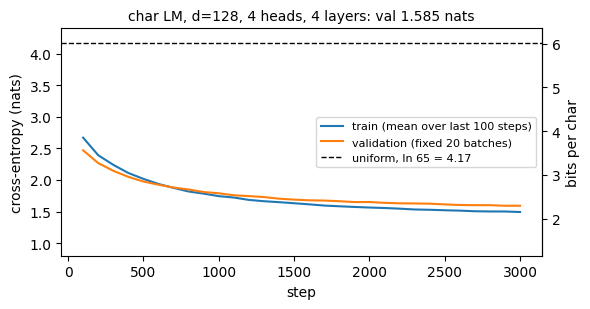

In [19]:
# learning curve
h = lm['hist']
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(h['step'], h['train'], label='train (mean over last 100 steps)')
ax.plot(h['step'], h['val'], label='validation (fixed 20 batches)')
ax.axhline(math.log(V), ls='--', color='k', lw=1, label=f'uniform, ln {V} = {math.log(V):.2f}')
ax.set_xlabel('step'); ax.set_ylabel('cross-entropy (nats)'); ax.set_ylim(0.8, 4.4); ax.legend(fontsize=8)
ax2 = ax.secondary_yaxis('right', functions=(lambda n: n / math.log(2), lambda b: b * math.log(2))); ax2.set_ylabel('bits per char')
ax.set_title(f'char LM, d={D_LM}, {HEADS_LM} heads, {LAYERS_LM} layers: val {lm["val_full"]:.3f} nats', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'p2_lm_curve.png', dpi=150); plt.show()

**Sampling:** start from "\n", keep the 20 best characters (top-k), divide the scores by the temperature and
pick one at random. Low temperature (0.2) = safe but repeats itself, high (1.5) = more random and more broken.

In [20]:
@torch.no_grad()
def generate(model, prompt, n_new, temperature, top_k=TOP_K, seed=0):
    model.eval(); gen = torch.Generator().manual_seed(seed)
    idx = encode(prompt)[None].to(device)                                  # (1, n)
    for _ in range(n_new):
        logits = model(idx[:, -model.ctx:])[:, -1] / temperature            # next-char scores (1, V)
        if top_k:
            kth = logits.topk(top_k).values[:, -1:]
            logits = logits.masked_fill(logits < kth, float('-inf'))       # drop everything below the top 20
        nxt = torch.multinomial(softmax(logits).cpu(), 1, generator=gen).to(device)
        idx = torch.cat([idx, nxt], dim=1)
    return decode(idx[0, len(prompt):].tolist())

PROMPT = '\n'
samples = {T: generate(lm_model, PROMPT, 500, T, seed=0) for T in [0.2, 0.8, 1.5]}
with open(SAMPLES, 'w', encoding='utf-8') as f:
    for T, s in samples.items():
        f.write(f'=== temperature {T} | top-k {TOP_K} | 500 characters | prompt "\\n" | sampling seed 0 ===\n{s}\n\n')
for T, s in samples.items():
    print(f'----- temperature {T} -----\n{s}\n')

----- temperature 0.2 -----
The father of the common of the first of the father
And the first of the state of the stands,
And the son the world of the part of the sent
That sent and the stand of the fair of the stand
The prove and the prince of the people of the stands
And the sent of the prince of the country,
And the first of the state of the state,
And the father of the prove and so the world
Than the senter of the stander of the country.

CORIOLANUS:
What I will be so so man a prove to the stander
Than the senter of th

----- temperature 0.8 -----
That make the prevail'd called and all the steen
Thou would for bear? he hath bleepen some on
For that of the wake a man: what thour needs,
And I have by the right in his gall to him,
Come, I shall be my prayer in mile.
Would the mark too the flain, in this med
And noble in born to the good to my hand.

LORD GHENRY VI:
With hath live tost me, and you of heavens.

GLOUCESTER:
And will the not blood, I not pretty,
Shall I am soul, and time 

## Task 5 - Analysis and ablations
### (a) Heatmaps
For each of the 16 heads I compute how far back it looks on average (mean attention distance).
I plot the most local head and the one that looks furthest back.

sentence: 'And you, good sir! Pray, have you not a daughter'
mean attention distance per (layer, head):
 [[11.44  7.89  1.66  2.8 ]
 [ 3.11  2.94  1.66  1.39]
 [ 1.22 11.64  3.11  2.09]
 [ 2.97  3.41  2.85  3.76]]
mean weight on the previous character:
 [[0.1  0.13 0.66 0.32]
 [0.26 0.23 0.45 0.46]
 [0.65 0.09 0.19 0.38]
 [0.32 0.28 0.42 0.26]]


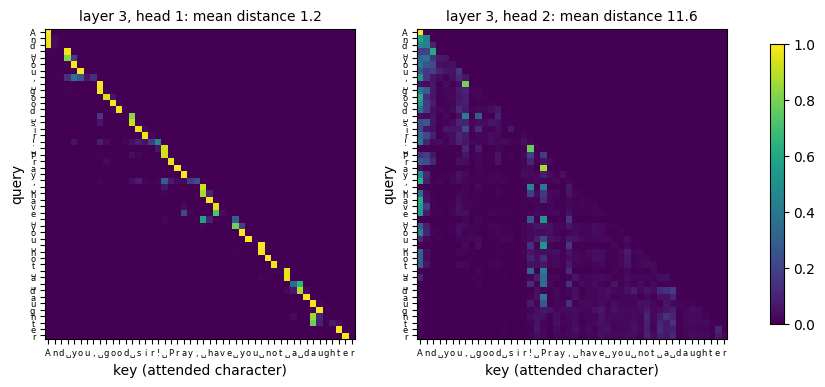

In [21]:
lines = decode(val_ids[:4000].tolist()).split('\n')
sentence = next(l for l in lines if 45 <= len(l) <= 60 and not l.endswith(':'))
ids = encode(sentence)[None].to(device)
with torch.no_grad():
    lm_model(ids)
W = torch.stack([blk.mha.last_weights[0] for blk in lm_model.blocks]).cpu()      # (layers, heads, n, n)
n = W.size(-1)
dist = (W * (torch.arange(n)[:, None] - torch.arange(n)[None, :]).float()).sum(-1).mean(-1)   # (layers, heads)
prev = torch.stack([W[..., i, i - 1] for i in range(1, n)], -1).mean(-1)                    # weight on the previous char
local = np.unravel_index(dist.argmin().item(), dist.shape)
far = np.unravel_index(dist.argmax().item(), dist.shape)
print(f'sentence: {sentence!r}')
print('mean attention distance per (layer, head):\n', dist.numpy().round(2))
print('mean weight on the previous character:\n', prev.numpy().round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
labels = [c if c != ' ' else '␣' for c in sentence]
for ax, (l, hd) in zip(axes, [local, far]):
    im = ax.imshow(W[l, hd], cmap='viridis', vmin=0, vmax=1)
    ax.set_xticks(range(n)); ax.set_xticklabels(labels, fontsize=6); ax.set_yticks(range(n)); ax.set_yticklabels(labels, fontsize=6)
    ax.set_xlabel('key (attended character)'); ax.set_ylabel('query')
    ax.set_title(f'layer {l + 1}, head {hd + 1}: mean distance {dist[l, hd]:.1f}', fontsize=10)
fig.colorbar(im, ax=axes, shrink=0.7)
plt.savefig(FIG / 'p2_heatmaps.png', dpi=150, bbox_inches='tight'); plt.show()

### (b) Heads = 1, 4, 8 at d = 128, and (c) no causal mask
All get 1,500 steps and the same seed. Without the mask each position can see the next character (its answer),
so I expect the training loss to go to almost 0 but the model to be useless for writing text.

In [22]:
abl_lm = {f'heads={hh}': run_lm(heads=hh, steps=ABL_STEPS) for hh in [1, 8]}
abl_lm['nomask'] = run_lm(causal=False, steps=ABL_STEPS)

In [23]:
# heads table and no-mask results
heads_rows = []
for hh in [1, 4, 8]:
    if hh == HEADS_LM:                                   # 4 heads = snapshot of the main run
        v, sps, hist, params = lm['snap']['val_full'], lm['snap']['sec_per_step'], lm['snap']['hist'], lm['params']
    else:
        r = abl_lm[f'heads={hh}']; v, sps, hist, params = r['val_full'], r['sec_per_step'], r['hist'], r['params']
    heads_rows.append(dict(heads=hh, d_k=D_LM // hh, params=params, val_loss=v, bpc=v / math.log(2), sec_per_step=sps, hist=hist))
    log_result(problem='problem2_charlm_heads', model=f'transformer_heads{hh}', seed=LM_SEED, seq_len=CTX, params=params,
               sec_per_epoch=round(sps * STEPS_PER_EPOCH, 2), val_loss_nats=round(v, 4), bits_per_char=round(v / math.log(2), 4),
               notes=f'steps={ABL_STEPS}; d={D_LM}; d_k={D_LM // hh}' + ('; taken from main run at this step' if hh == HEADS_LM else '')
                     + f'; hw={(lm if hh == HEADS_LM else abl_lm[f"heads={hh}"])["hw"]}')
heads_df = pd.DataFrame(heads_rows).drop(columns='hist')
print(heads_df.round(4).to_string(index=False)); heads_df.to_csv(FIG / 'p2_heads_table.csv', index=False)

nm = abl_lm['nomask']
nm_model = CharTransformer(causal=False).to(device); nm_model.load_state_dict(nm['state'])
nm_sample = generate(nm_model, PROMPT, 300, 0.8, seed=0)
log_result(problem='problem2_charlm_nomask', model='transformer_no_causal_mask', seed=LM_SEED, seq_len=CTX, params=nm['params'],
           sec_per_epoch=round(nm['sec_per_step'] * STEPS_PER_EPOCH, 2), val_loss_nats=round(nm['val_full'], 4),
           bits_per_char=round(nm['val_full'] / math.log(2), 4),
           notes=f'steps={ABL_STEPS}; val loss evaluated without mask (future visible); same weights with causal mask at '
                 f'eval = {nm["val_full_causal_eval"]:.4f} nats; hw={nm["hw"]}')
print(f'\nno mask: val loss {nm["val_full"]:.4f} nats with the future visible, '
      f'{nm["val_full_causal_eval"]:.4f} nats when the causal mask is switched on at test time')
print(f'masked model at the same step: {lm["snap"]["val_full"]:.4f} nats')
print('----- no-mask model, temperature 0.8 -----\n' + nm_sample)

 heads  d_k  params  val_loss    bpc  sec_per_step
     1  128  810049    1.6874 2.4344        0.0303
     4   32  810049    1.6861 2.4325        0.0434
     8   16  810049    1.7090 2.4655        0.0611

no mask: val loss 0.0183 nats with the future visible, 9.5933 nats when the causal mask is switched on at test time
masked model at the same step: 1.6861 nats
----- no-mask model, temperature 0.8 -----











































ssssss

















































































a nen my my tho wepe yt te.


S Iiserd.

HAn tha an she.

Four h.

Had yepr.

Fand-mely.
Woe nor say, ins od le flaim winl the me tho she.

At sha youn att ghe sthem mal


In [24]:
# fair timing for 1, 4, 8 heads (the training runs above ran at different times, so their times don't compare)
head_time = {}
for hh in [1, 4, 8]:
    set_seed(0); m_ = CharTransformer(heads=hh).to(device).train()
    opt_ = torch.optim.Adam(m_.parameters(), lr=LR); gen = torch.Generator().manual_seed(0)
    ts = []
    for i in range(6):
        x, y = get_batch(train_ids, LM_BATCH, CTX, gen); t0 = time.time()
        loss = lm_loss(m_, x, y); opt_.zero_grad(); loss.backward(); opt_.step()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        if i > 0:                                        # skip the first step (warm-up)
            ts.append(time.time() - t0)
    head_time[hh] = float(np.median(ts))
heads_df['controlled_s_per_step'] = [head_time[hh] for hh in heads_df.heads]
print(heads_df.round(4).to_string(index=False)); heads_df.to_csv(FIG / 'p2_heads_table.csv', index=False)

 heads  d_k  params  val_loss    bpc  sec_per_step  controlled_s_per_step
     1  128  810049    1.6874 2.4344        0.0303                 0.0286
     4   32  810049    1.6861 2.4325        0.0434                 0.0411
     8   16  810049    1.7090 2.4655        0.0611                 0.0590


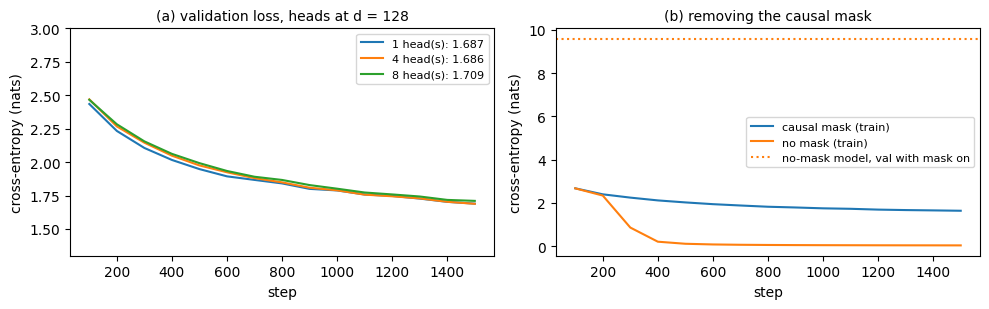

In [25]:
# plots for (b) and (c)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for row in heads_rows:
    hh = row['hist']
    axes[0].plot(hh['step'], hh['val'], label=f"{row['heads']} head(s): {row['val_loss']:.3f}")
axes[0].set_title(f'(a) validation loss, heads at d = {D_LM}', fontsize=10)
mh = lm['snap']['hist']
axes[1].plot(mh['step'], mh['train'], label='causal mask (train)')
axes[1].plot(nm['hist']['step'], nm['hist']['train'], label='no mask (train)')
axes[1].axhline(nm['val_full_causal_eval'], ls=':', color='tab:orange', label='no-mask model, val with mask on')
axes[1].set_title('(b) removing the causal mask', fontsize=10)
for ax in axes:
    ax.set_xlabel('step'); ax.set_ylabel('cross-entropy (nats)'); ax.legend(fontsize=8)
axes[0].set_ylim(1.3, 3.0)
plt.tight_layout(); plt.savefig(FIG / 'p2_heads_nomask.png', dpi=150); plt.show()

### (d) Time and memory vs context length
Attention has n² scores, so doubling n should make that part 4x bigger. I time one forward + backward step
(batch 16) for n = 64, 128, 256, 512, and count the memory autograd keeps for the backward pass.

In [26]:
def saved_bytes(model, x, y):
    # adds up every tensor autograd saves for backward (each piece of memory counted once)
    seen, total = set(), [0]
    def pack(t):
        key = (t.untyped_storage().data_ptr(), t.untyped_storage().nbytes())
        if key not in seen:
            seen.add(key); total[0] += key[1]
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = lm_loss(model, x, y)
    loss.backward()
    return total[0]

ctx_rows = []
for n_ctx in [64, 128, 256, 512]:
    set_seed(0); m_ = CharTransformer(ctx=n_ctx).to(device).train()      # new untrained model
    gen = torch.Generator().manual_seed(0); x, y = get_batch(train_ids, 16, n_ctx, gen)
    mem = saved_bytes(m_, x, y); m_.zero_grad()
    if device.type == 'cuda':
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    times = []
    for i in range(6):
        t0 = time.time(); lm_loss(m_, x, y).backward(); m_.zero_grad()
        if device.type == 'cuda':
            torch.cuda.synchronize()
        if i > 0:                                        # skip warm-up
            times.append(time.time() - t0)
    peak = torch.cuda.max_memory_allocated() / 2 ** 20 if device.type == 'cuda' else float('nan')
    attn_mb = LAYERS_LM * 16 * HEADS_LM * n_ctx ** 2 * 4 * 3 / 2 ** 20   # scores, weights, dropout copy (float32)
    ctx_rows.append(dict(context=n_ctx, ms_per_batch=1000 * np.median(times), saved_MB=mem / 2 ** 20, attn_part_MB=attn_mb, cuda_peak_MB=peak))
ctx_df = pd.DataFrame(ctx_rows)
ctx_df['time_ratio'] = ctx_df.ms_per_batch / ctx_df.ms_per_batch.shift(1)
ctx_df['mem_ratio'] = ctx_df.saved_MB / ctx_df.saved_MB.shift(1)
print(ctx_df.round(2).to_string(index=False)); ctx_df.to_csv(FIG / 'p2_context_table.csv', index=False)

 context  ms_per_batch  saved_MB  attn_part_MB  cuda_peak_MB  time_ratio  mem_ratio
      64         13.21     52.65          12.0         91.68         NaN        NaN
     128         13.94    128.28          48.0        170.02        1.05       2.44
     256         30.56    357.65         192.0        442.41        2.19       2.79
     512         94.95   1128.76         768.0       1413.56        3.11       3.16


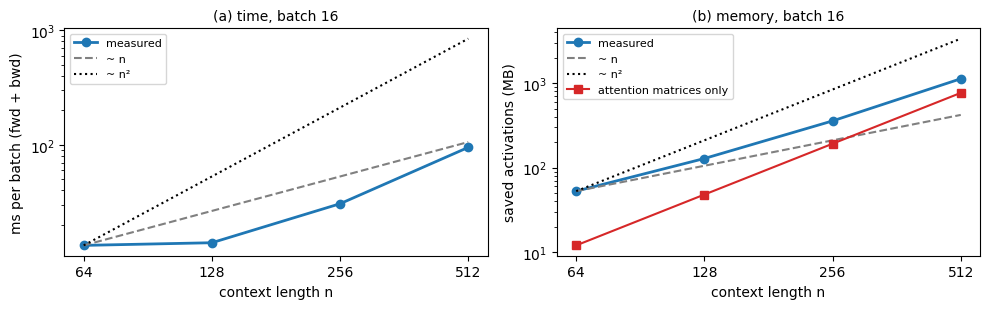

In [27]:
# plot with ~n and ~n² lines to compare
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
ns = ctx_df.context.values
for ax, col, lab in [(axes[0], 'ms_per_batch', 'ms per batch (fwd + bwd)'), (axes[1], 'saved_MB', 'saved activations (MB)')]:
    v = ctx_df[col].values
    ax.plot(ns, v, 'o-', lw=2, label='measured')
    ax.plot(ns, v[0] * ns / ns[0], '--', color='gray', label='~ n')
    ax.plot(ns, v[0] * (ns / ns[0]) ** 2, ':', color='k', label='~ n²')
    ax.set_xscale('log', base=2); ax.set_yscale('log'); ax.set_xticks(ns); ax.set_xticklabels(ns)
    ax.set_xlabel('context length n'); ax.set_ylabel(lab); ax.legend(fontsize=8)
axes[1].plot(ns, ctx_df.attn_part_MB, 's-', color='tab:red', label='attention matrices only')
axes[1].legend(fontsize=8)
axes[0].set_title('(a) time, batch 16', fontsize=10); axes[1].set_title('(b) memory, batch 16', fontsize=10)
plt.tight_layout(); plt.savefig(FIG / 'p2_context_scaling.png', dpi=150); plt.show()

## Bonus - KV cache
Without a cache, every new character runs the model over the whole text again. With the cache each layer keeps
its old keys and values, so only the new character goes through. I generate 127 characters greedily (no
randomness) both ways, so the text should be exactly the same.

In [28]:
@torch.no_grad()
def greedy(model, prompt_ids, n_new, use_cache):
    model.eval(); idx = prompt_ids.clone()
    if not use_cache:
        for _ in range(n_new):
            idx = torch.cat([idx, model(idx)[:, -1].argmax(-1, keepdim=True)], 1)   # whole text every time
        return idx
    caches = [dict() for _ in model.blocks]                 # one cache per layer
    logits = model(idx, caches, start=0)                    # prompt fills the cache
    for _ in range(n_new):
        nxt = logits[:, -1].argmax(-1, keepdim=True); idx = torch.cat([idx, nxt], 1)
        if idx.size(1) == model.ctx + 1:
            break
        logits = model(nxt, caches, start=idx.size(1) - 1)  # only the new character
    return idx

p_ids = encode('\n')[None].to(device)
res = {}
for use in [False, True]:
    greedy(lm_model, p_ids, 10, use)                        # warm-up
    t0 = time.time()
    for _ in range(3):
        out = greedy(lm_model, p_ids, CTX - 1, use)
    res[use] = ((time.time() - t0) / 3, out)
same = torch.equal(res[False][1], res[True][1])
speedup = res[False][0] / res[True][0]
print(f'no cache {res[False][0] * 1000:.0f} ms, with cache {res[True][0] * 1000:.0f} ms for {CTX - 1} characters -> {speedup:.1f}x; identical output: {same}')
log_result(problem='bonus_kv_cache', model=f'transformer_d{D_LM}_h{HEADS_LM}_l{LAYERS_LM}', seed=LM_SEED, seq_len=CTX, params=lm['params'],
           notes=f'greedy {CTX - 1} chars; no cache {res[False][0]:.3f}s; kv cache {res[True][0]:.3f}s; speedup={speedup:.2f}x; identical={same}; hw={HW}')

no cache 460 ms, with cache 421 ms for 127 characters -> 1.1x; identical output: True


In [29]:
print(pd.read_csv(RESULTS).query("problem.str.startswith('problem2') or problem.str.startswith('bonus')", engine='python')
      [['problem', 'model', 'seed', 'test_acc', 'val_loss_nats', 'bits_per_char']].to_string(index=False))

               problem                      model  seed  test_acc  val_loss_nats  bits_per_char
  problem2_har_encoder           encoder_pos_none    11    0.9074            NaN            NaN
  problem2_har_encoder            encoder_pos_sin    11    0.8901            NaN            NaN
  problem2_har_encoder        encoder_pos_learned    11    0.9175            NaN            NaN
  problem2_har_encoder           encoder_pos_none    23    0.9148            NaN            NaN
  problem2_har_encoder            encoder_pos_sin    23    0.9213            NaN            NaN
  problem2_har_encoder        encoder_pos_learned    23    0.9335            NaN            NaN
  problem2_har_encoder           encoder_pos_none    37    0.9328            NaN            NaN
  problem2_har_encoder            encoder_pos_sin    37    0.9057            NaN            NaN
  problem2_har_encoder        encoder_pos_learned    37    0.8982            NaN            NaN
       problem2_charlm     transformer_d